In [1]:
%reset -f

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap
from tensorflow.keras.models import load_model
import torch
import torch.nn as nn
import joblib
import json
from pathlib import Path
from datetime import datetime

import sys
sys.path.append("../../tools")
import architec as acht
import evaluation as eva
import prepare as prep
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(acht)


In [3]:
rep = 7 # When rep=7, overall R2=0.72, and the test set contains more multi-stable samples with >10 states
load_dir1 = Path(f"../../saved_models/num_stable_states_15fold/sp3to20_NS_transpt3_r{rep}")
#load_dir1 = Path(f"../../saved_models/num_stable_states/sp3to20_NS_transpt_R63")

nmodel = func.load_saved_model_NS(load_dir1, device)
nevaluator = func.TrteEvaluator(nmodel)

split_df = pd.read_csv(f"split_MD_v1/split_MD_{rep}.csv")
folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20"

narray = prep.load_split_dataset(
    split_df,
    folder_path,
    richness_list=[20],
    #richness_list=list(range(3,21)),
    subset="te",
    sample_size=15000,
)

# Evaluate the model on the test set
y_te, y_prob = nevaluator.predict_array_NS(narray, device, sample_size=None)

y_pred = np.argmax(y_prob, axis=1)

metrics = eva.eval_multiclass(nmodel["n_class"], y_te, y_prob)
df_metrics = pd.DataFrame([metrics])
display(df_metrics)


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


te shape = (15000, 465)


,Accuracy,Balanced_Acc,F1_macro,F1_weighted,class_dist,Top2_Acc,MAE_ord_expect,RMSE_ord_expect,R2_ord_expect,MAE_ord_argmax,RMSE_ord_argmax
0,0.376,0.206784,0.202971,0.358931,"[0.2618, 0.2198, 0.19393333333333335, 0.141666...",0.611133,0.980879,1.293431,0.649985,0.9528,1.368405


C:\Users\HW\AppData\Local\Temp\ipykernel_22344\2306739503.py:44: RuntimeWarning: invalid value encountered in divide
  cm_plot = cm.astype(float) / cm.sum(axis=0, keepdims=True)


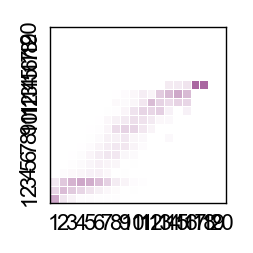

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8, # axis label (text)
    'axes.titlesize': 9,
    'axes.linewidth': 0.5, # axis border line width
    'legend.fontsize': 7, # legend (legend content, not legend title)
    'xtick.major.width': 0.5, # tick line width
    'ytick.major.width': 0.5,
    'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
    'ytick.major.size': 1.5,
    'xtick.labelsize': 8, # x-axis tick label (numbers)
    'ytick.labelsize': 8,
    'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

    'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
    'ps.fonttype': 42
})

def ConfusionMatrix_MultiClass(
        n_class,
        y_true,
        y_pred,
        pdfname=None,
        normalize=True
):
    '''
    y_true and y_pred must in range [0, n_class-1], instead of [1, n_class]
    '''

    y_true = np.asarray(y_true) # convert to numpy array
    y_pred = np.asarray(y_pred)

    labels = np.arange(n_class)
    cm = confusion_matrix(y_pred, y_true, labels=labels) # rows are predicted values, columns are true values

    # column normalization
    if normalize:
        cm_plot = cm.astype(float) / cm.sum(axis=0, keepdims=True)
        cm_plot = np.nan_to_num(cm_plot)
        fmt = ".2f"
        vmax = 1
    else:
        cm_plot = cm
        fmt = "d"
        vmax = np.max(cm)

    cm_plot = cm_plot[::-1, :] # flip the y-axis

    #colors = ["#ff993f00", "#e8d0ae"]
    colors = ["#ffffff", "#aa67a1"]

    my_cmap = LinearSegmentedColormap.from_list('my_cmap', colors)

    plt.figure(figsize=(1.1, 1.1), dpi=200)

    ax = sns.heatmap(
        cm_plot,
        annot=False,
        fmt=fmt,
        cmap=my_cmap,
        vmin=0,
        vmax=vmax,
        square=True,
        cbar=False,
        linewidths=0.3,
        linecolor='white'
    )

    ax.set_xticks([i + 0.5 for i in range(len(labels))])
    ax.set_yticks([i + 0.5 for i in range(len(labels))])

    ax.set_xticklabels(labels + 1)
    ax.set_yticklabels((labels + 1)[::-1])

    ax.tick_params(axis='both', which='both', length=0)

    threshold = 0.5 if normalize else vmax * 0.5

    for idx, text in enumerate(ax.texts):

        row = idx // cm_plot.shape[1]
        col = idx % cm_plot.shape[1]
        value = cm_plot[row, col]
        text.set_color('white' if value > threshold else 'black')

    # border
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")

    plt.subplots_adjust(
        left=0.18,
        right=0.98,
        bottom=0.18,
        top=0.98
    )

    if pdfname is not None:
        plt.savefig(
            pdfname,
            dpi=1000,
            bbox_inches="tight",
            transparent=True
        )

    plt.show()

ConfusionMatrix_MultiClass(nmodel["n_class"], y_te, y_pred, 
                           #f"Con_NS_v3_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf"
                           )
